# 2 · The Melito storm, 10 October 2026

Landslides hit the Reggio Calabria area on 10 October 2026. This notebook reads the hourly radar rain at Melito di Porto Salvo from the benchmark, cuts it into events, and compares them with the threshold of southern Italy. Then it breaks the series on purpose, twice, to show the two rules of version 0.2.

The series is the DPC product SRT1 (radar only), © Dipartimento della Protezione Civile, CC BY-SA 4.0. Radar rain is not rain-gauge rain, and the thresholds are fitted on gauges.

> **A threshold exceeded is not an alert.** It says the rain is like the rain that triggered landslides before. The official alert in Italy is the criticality bulletin of the Dipartimento della Protezione Civile.

In [1]:
import csv
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt

from rainfall_thresholds import ITALICA_T5, latest_event, reconstruct_events, strongest_event

SERIES = Path("../benchmarks/series")


def read(name):
    with (SERIES / name).open(encoding="utf-8") as f:
        rows = csv.DictReader(line for line in f if not line.startswith("#"))
        return [
            (
                datetime.fromisoformat(r["time"].replace("Z", "+00:00")),
                float(r["mm"]) if r["mm"] else None,
            )
            for r in rows
        ]


melito = read("melito-srt1.csv")
threshold = ITALICA_T5["southern"]
print(len(melito), "hours,", round(sum(mm for _, mm in melito), 1), "mm")

72 hours, 166.4 mm


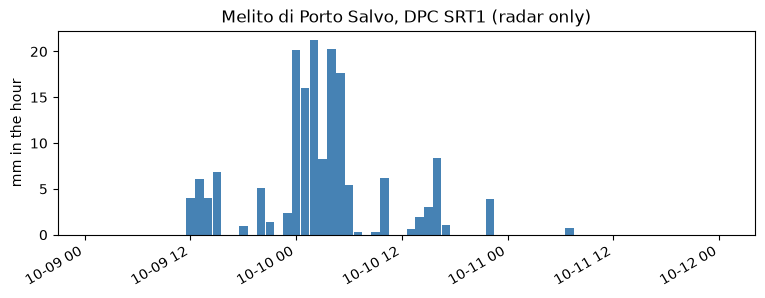

In [2]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar([t for t, _ in melito], [mm for _, mm in melito], width=0.04, color="steelblue")
ax.set_ylabel("mm in the hour")
ax.set_title("Melito di Porto Salvo, DPC SRT1 (radar only)")
fig.autofmt_xdate()
plt.show()

## Events, and where they stand

In [3]:
events = reconstruct_events(melito, no_rain_break_hours=6, min_event_mm=2.0, source="DPC SRT1")
for e in events:
    x = threshold.exceedance(e.intensity_mm_h, e.duration_hours)
    need = threshold.cumulated(e.duration_hours)
    when = f"{e.start:%d/%m %H:%M} -> {e.end:%d/%m %H:%M}"
    rain = f"{e.total_mm:5.1f} mm in {e.duration_hours:2.0f} h (T5 asks {need:4.1f} mm)"
    print(f"{when}  {rain}  {x:+.2f} decades  [{e.source}]")

09/10 12:00 -> 10/10 22:00  165.7 mm in 35 h (T5 asks 30.9 mm)  +0.73 decades  [DPC SRT1]


One event, from the afternoon of the 9th to the night of the 10th: about five times the intensity of the line (10^0.73). On this series the last event and the strongest are the same.

## Break it once: drizzle after the storm

The benchmark keeps a case built from Melito's storm hours, then six dry hours and 2.5 mm of drizzle. It was not observed: it tests which event is read.

In [4]:
drizzle = read("melito-then-drizzle.csv")
events = reconstruct_events(drizzle, no_rain_break_hours=6, min_event_mm=2.0)
for name, e in (
    ("latest_event", latest_event(events)),
    ("strongest_event", strongest_event(events, threshold)),
):
    x = threshold.exceedance(e.intensity_mm_h, e.duration_hours)
    print(f"{name:>16}: {e.total_mm:5.1f} mm in {e.duration_hours:.0f} h -> {x:+.2f}")

    latest_event:   2.5 mm in 2 h -> -0.65
 strongest_event: 109.4 mm in 8 h -> +0.78


`latest_event` reads the drizzle and forgets the storm. That is what version 0.1 did, and what a monitoring loop built on it saw. `strongest_event` keeps the storm.

## Break it twice: hours not measured

Three hours of the storm are missing, as under a blind radar or a lost frame. `None` is not zero.

In [5]:
gap = read("melito-gap.csv")
(e,) = reconstruct_events(gap, no_rain_break_hours=6, min_event_mm=2.0)
x = threshold.exceedance(e.intensity_mm_h, e.duration_hours)
print(f"{e.total_mm:.1f} mm measured in {e.duration_hours:.0f} h")
print(f"{e.unmeasured_hours} hours not measured, fully measured: {e.fully_measured}")
print(f"{x:+.2f} decades above T5 (a lower bound)")

59.6 mm measured in 8 h
3 hours not measured, fully measured: False
+0.51 decades above T5 (a lower bound)


The event is not split by the gap, and what was measured is already above the line. Had the three hours been written as `0`, the result would look complete and be wrong.